# Task 2 - Random Forest random search

This notebook searches for the best Random Forest hyperparameters using stratified cross-validation on the training partition. The search maximises Normal-class precision, matching the existing Random Forest classification notebook, and evaluates the selected model once on the held-out validation partition.

The search includes:

- `n_estimators`: 50-300;
- `max_depth`: 5-20;
- `min_samples_leaf`: 1-8;
- `criterion`: Gini, entropy, and log loss;
- `min_samples_split`: 5-20.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, make_scorer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

RANDOM_STATE = 12
TEST_SIZE = 0.20
CV_SPLITS = 5
N_ITER = 30
SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = ["Normal", "Sag", "Swell", "Interruption", "Harmonics", "Sag_harmonics", "Swell_harmonics", "Transient", "Flicker"]
NORMAL_LABEL = "Normal"
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {"avg abs": "F2", "sd": "F3", "max": "F4", "min": "F5", "no. pks": "F6", "sd fma": "F7", "sd fma 3": "F1", "no. pt near 0": "F8"}

def normal_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[NORMAL_LABEL], average="macro", zero_division=0)

normal_precision_scorer = make_scorer(normal_precision)


## 1. Load the data and create a stratified train/validation split


In [2]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)

current = Path.cwd().resolve()
DATA_ROOT = next((path / "Code" / "data" for path in [current, *current.parents] if (path / "Code" / "data").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Could not find Code/data. Run this notebook inside the project repository.")

dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(f"Using data from: {DATA_ROOT}")
print(f"Loaded {len(dataset):,} samples with {X.shape[1]} features.")
print(f"Training samples: {len(X_train):,}; validation samples: {len(X_valid):,}")


Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/data
Loaded 6,705 samples with 8 features.
Training samples: 5,364; validation samples: 1,341


## 2. Random search over the Random Forest hyperparameters

`min_samples_split` is sampled from 5 through 20 inclusive. The three supported split criteria are tested: Gini impurity, entropy, and log loss.


In [5]:
PARAM_DISTRIBUTIONS = {
    "n_estimators": list(range(50, 501)),
    "max_depth": list(range(5, 21)),
    "min_samples_leaf": list(range(1, 9)),
    "criterion": ["gini", "entropy", "log_loss"],
    "min_samples_split": list(range(5, 21)),
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    param_distributions=PARAM_DISTRIBUTIONS,
    n_iter=N_ITER,
    scoring={
        "normal_precision": normal_precision_scorer,
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro",
    },
    refit="normal_precision",
    cv=StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=False,
)
random_search.fit(X_train, y_train)

random_results = pd.DataFrame(random_search.cv_results_).sort_values(
    "mean_test_normal_precision", ascending=False
).reset_index(drop=True)
result_columns = [
    "params", "mean_test_normal_precision", "mean_test_accuracy",
    "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
]
display(random_results[result_columns].head(10))
print("Best cross-validated Normal precision:", random_search.best_score_)
print("Selected configuration:", random_search.best_params_)


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/

,params,mean_test_normal_precision,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro
0,"{'n_estimators': 316, 'min_samples_split': 18,...",0.952661,0.985832,0.986000,0.985829,0.985850
1,"{'n_estimators': 377, 'min_samples_split': 20,...",0.952661,0.985832,0.986001,0.985829,0.985851
2,"{'n_estimators': 135, 'min_samples_split': 8, ...",0.951057,0.984900,0.985084,0.984896,0.984915
3,"{'n_estimators': 407, 'min_samples_split': 9, ...",0.949745,0.985459,0.985660,0.985458,0.985483
4,"{'n_estimators': 220, 'min_samples_split': 19,...",0.949718,0.985645,0.985840,0.985643,0.985671
5,"{'n_estimators': 119, 'min_samples_split': 20,...",0.949663,0.985272,0.985487,0.985269,0.985289
6,"{'n_estimators': 359, 'min_samples_split': 7, ...",0.949623,0.985272,0.985461,0.985269,0.985295
7,"{'n_estimators': 108, 'min_samples_split': 7, ...",0.949393,0.985086,0.985264,0.985084,0.985104
8,"{'n_estimators': 365, 'min_samples_split': 14,...",0.948008,0.985272,0.985468,0.985271,0.985296
9,"{'n_estimators': 409, 'min_samples_split': 14,...",0.948008,0.985272,0.985468,0.985271,0.985296


Best cross-validated Normal precision: 0.9526613493540287
Selected configuration: {'n_estimators': 316, 'min_samples_split': 18, 'min_samples_leaf': 1, 'max_depth': 19, 'criterion': 'log_loss'}


## 3. Evaluate the selected Random Forest


,Metric,Value
0,Accuracy,0.982103
1,Normal precision,0.928105
2,Macro precision,0.982378
3,Macro recall,0.982103
4,Macro F1,0.982150
5,Weighted F1,0.982150


,precision,recall,f1-score,support
Normal,0.928105,0.953020,0.940397,149.0
Sag,1.000000,0.979866,0.989831,149.0
Swell,1.000000,1.000000,1.000000,149.0
Interruption,0.980263,1.000000,0.990033,149.0
Harmonics,1.000000,1.000000,1.000000,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.947020,0.959732,0.953333,149.0
Flicker,0.986014,0.946309,0.965753,149.0


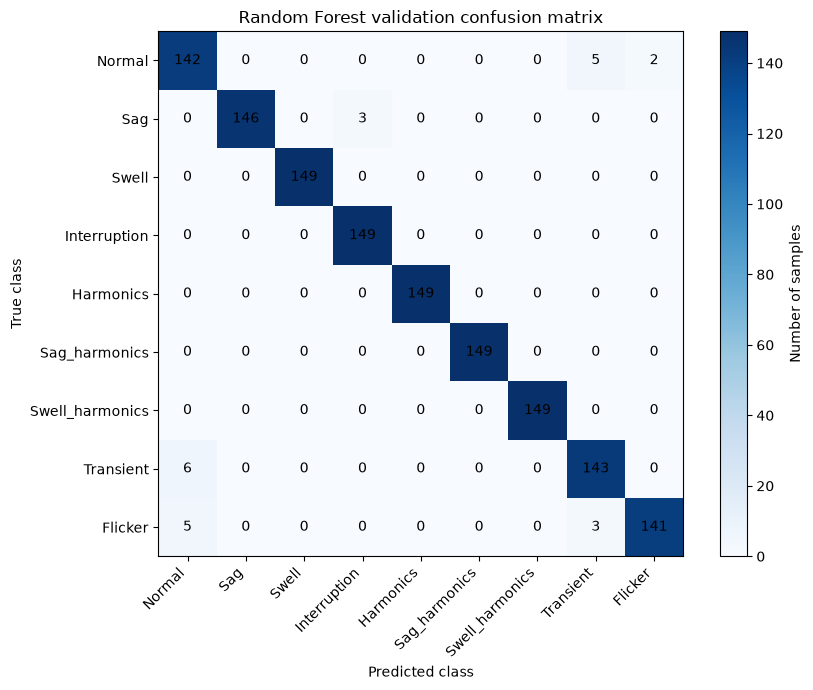

In [4]:
y_pred = random_search.best_estimator_.predict(X_valid)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Normal precision", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
    "Value": [
        accuracy_score(y_valid, y_pred),
        normal_precision(y_valid, y_pred),
        precision_score(y_valid, y_pred, average="macro", zero_division=0),
        recall_score(y_valid, y_pred, average="macro", zero_division=0),
        f1_score(y_valid, y_pred, average="macro", zero_division=0),
        f1_score(y_valid, y_pred, average="weighted", zero_division=0),
    ],
})
display(metrics)

report = pd.DataFrame(classification_report(y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0)).T
display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

confusion = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(confusion, cmap="Blues")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Random Forest validation confusion matrix")
fig.colorbar(image, ax=ax, label="Number of samples")
plt.tight_layout()
plt.show()
